# Part 1. Set up the notebook
Copyright (C) 2026 Marianna Foschi, Antonio Fuentes, Brandon Zhao

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

Reference: Foschi, M., Zhao, B., Fuentes, A. et al., "Video reconstruction of variable VLBI observations with neural fields." Under rev. (2026)

### Step 1: Enable the GPU runtime

1. In the Colab menu, click Runtime → Change runtime type
2. Under "Hardware accelerator", select T4 GPU
3. Click Save

### Step 2: Install packages

1. Run the following cell
2. A pop up window should appear, select "Restart session"
3. Run the cell again

In [1]:
# !pip install git+https://github.com/mariannafoschi/kine.git
!pip install jax[cuda12] -f https://storage.googleapis.com/jax-releases/jax_cuda_releases.html
!pip install ehtim finufft flax optax

Looking in links: https://storage.googleapis.com/jax-releases/jax_cuda_releases.html


This requires Kine to be modified, so clone the repo in your Drive with the changes in kine/kine/obsdata.py from this commit. Change the path in sys.path.insert to the path of your kine

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.insert(0, '/content/drive/MyDrive/CS163/kine/')

Mounted at /content/drive


### Step 3: Import packages

Ensure all packages load correctly

In [3]:
import glob
import numpy as np
import ehtim as eh
import ehtim.const_def as ehc
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage
from tqdm.notebook import tqdm
from collections import OrderedDict as odict

import jax
import optax
from flax import linen as nn
from jax import numpy as jnp

import kine.model as mo
import kine.obsdata as ob
import kine.trainer as tr
import kine.utils as ut
import kine.video as vi

import pandas as pd

print("✓ All imports successful")

Welcome to eht-imaging!


✓ All imports successful


**Note:** GPU-accelerated NUFFT is not available in colab but it is implemented in the code. It is designed for multi-epoch imaging of large datasets.

# Part 2. Upload observations and set imaging parameters
### Step 1: Upload observation file to Colab
Run the following cell and click "Choose Files" to select the observations to image. To follow thi tutorial, select any of the observations in the folder "data" of the Kine repository.

In [4]:
from google.colab import files
uploaded = files.upload()

Saving DL_Tau_selfcal_cont_bin60s_1chan_1freq.txt to DL_Tau_selfcal_cont_bin60s_1chan_1freq.txt


### Step 2: Set imaging parameters
**Note:** In the actual code this is done by loading a .yaml file, but for this Colab tutorial they are set directly in the notebook.

In [5]:
# Data pre-processing
# -----------------------------
# Time averaging
tavg = 60
# Systematic noise
syserr = 0.01
# Minimum number of baselines per data snapshot
min_bl = 0

# Coordinates and data products
# -----------------------------
# Field of view (uas)
fov_uas = 4000000
# Space resolution (pix)
npix = 128
npix_out = 256
# Data products
data_prod = ['visI']

# Network initialization
# -----------------------------
init_params = {
  'fwhm': 2000000,
  'blur': 500000,
  'posx': 0,
  'posy': 0
}
# Training
# -----------------------------
# Initialization seed
seed = 1
# Number of epochs
niter = 5000
initniter = 5000
# Degrees of positional encoding ([t, x, y])
nposenc = [0, 0]
# Network parameters
depth = 4
width = 256
outshift = 10
scaling_i = 1

# Part 3. Run the algorithm
### Step 1: Load and preprocess the observations

In [6]:
source = 'DL Tau'
ra = 4.5609 # hours
dec = 25.3439 # deg
mjd = 57992 # Modified Julian Day
rf = 2.180112085974 *1e11 # Hz
bw = 1.781250000000 *1e9 # Hz
timetype = 'UTC' #
polrep = 'stokes' # if you save IQUV visibilities instead of XX,YY,XY,YX

In [7]:
raw_data = pd.read_csv('./DL_Tau_selfcal_cont_bin60s_1chan_1freq.txt', sep=r'\s\s+', engine='python')

df = pd.DataFrame(columns=dict(ehc.DTPOL_STOKES).keys())
df['time'] = raw_data['Time'] / 3600 - mjd * 24  # raw_data Time is given in MJD in seconds; we want to convert to hours of fractional MJD
df[['tint', 'u', 'v']] = raw_data[['Exposure', 'u[lambda]', 'v[lambda]']]
df[['t1', 't2']] = raw_data[['Ant1', 'Ant2']].astype(str)
df[['tau1', 'tau2']] = 0.0
df['vis'] = 1 / 2 * (raw_data['Real XX'] + raw_data['Real YY'] + 1j * raw_data['Imag XX'] + 1j * raw_data['Imag YY']) # I visibility
df['sigma'] = np.sqrt(1 / raw_data['Weight XX'] + 1 / raw_data ['Weight YY']) # I sigma.
datatable = df.to_records(index=False, column_dtypes=dict(ehc.DTPOL_STOKES))

In [8]:
tarr = pd.DataFrame(columns=dict(ehc.DTARR).keys())
tarr['site'] = sorted(list(set(df['t1']).union(df['t2'])))
tarr['x'] = 2.225e6  # given by claude as approximate ALMA position
tarr['y'] = -5.440e6
tarr['z']= -2.482e6

tarr[['sefdr','sefdl']] = 0.0
tarr[['dr','dl']] = 0j
tarr[['fr_par', 'fr_elev','fr_off']] = 0.0
tarr = tarr.to_records(index=False, column_dtypes=dict(ehc.DTARR))

Calculate the expected angular resolution and largest recoverable scale, to set the initial FOV and number of pixels above.

Angular resolution = wavelength / maximum_baseline = wavelength / maximum_baseline = wavelength / (wavelength * np.sqrt(u ** 2 + u ** 2).max()) = 1 / np.sqrt(u ** 2 + u ** 2).max(), when u and v units are the number of wavelengths.

Largest recoverable scale is the same, but taking the minimum baseline instead.

In this case, we get around 14 arcseconds for the initial FOV, but the actual source is much smaller, so we adjust the FOV to be 4 arcseconds instead. Angular resolution is around 90 mas, so our pixels should be roughly on the order of 90/5 to 90/3 mas, or 18 to 30 mas. When the FOV is 4 as, this gives 133 to 222 pixels, so 128 or 256 pixels is a perfect choice.

In [9]:
angular_resolution = 1 / np.sqrt(df['u'] ** 2 + df['v'] ** 2).max() # in radians
print(f'expected angular resolution: {angular_resolution * 180 / np.pi * 60 * 60 * 1e3} mas') # in milli arc seconds
fov = 1 / np.sqrt(df['u'] ** 2 + df['v'] ** 2).min() # in radians. Technically the largest recoverable scale, not exactly the FOV?
print(f'largest recoverable scale: {fov * 180 / np.pi * 60 * 60 * 1e3} mas') # in milli arc seconds


expected angular resolution: 93.57321864508957 mas
largest recoverable scale: 14314.194474773249 mas


In [10]:
# Set random keys
rkey = jax.random.PRNGKey(seed)
np.random.seed(seed)

print('Loading data...')

# Load and pre-process data
obs = ob.Obsdata(ra=ra, dec=dec, rf=rf, bw=bw, datatable=datatable, tarr=tarr, polrep=polrep, source=source, mjd=mjd, timetype=timetype)

obs = obs.avg_coherent(tavg)
obs = obs.add_fractional_noise(syserr)

# Get zbl flux density)
totflux = obs.get_zbl()

Loading data...


/usr/local/lib/python3.12/dist-packages/ehtim/statistics/dataframes.py:198: FutureWarning: The provided callable <function min at 0x7f8e80d4e520> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  vis_avg = vis.groupby(grouping).agg(aggregated).reset_index()
/usr/local/lib/python3.12/dist-packages/ehtim/statistics/dataframes.py:198: FutureWarning: The provided callable <function min at 0x7f8e80d4e520> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  vis_avg = vis.groupby(grouping).agg(aggregated).reset_index()
/usr/local/lib/python3.12/dist-packages/ehtim/statistics/dataframes.py:198: FutureWarning: The provided callable <function mean at 0x7f8e80d4ede0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable w

### Step 2: Prepare the grid of input coordinates, extract the data products and the matrices for the Fourier transform.

In [11]:
# Set up grid of input coordinates and data products
print('Set up grid of input coordinates...')

# Field of view
fov = fov_uas * eh.RADPERUAS

# Set 2D coordinate grids
grid = ut.get_grid(npix, npix)

# Set polarization channels
outdim = 1
if 'visQ' in data_prod: outdim = 4
if 'visV' in data_prod: outdim = 5

# Set empty image for image metadata and dimensions
improxy = eh.image.make_square(obs, npix, fov, pol_prim='I')

# Compute lists of data products (target), uncertainties (sigma),
# and Fourier matrix (A) at each observed time
print('Retrieving data products from each epoch...')

data = {}
for dtype in data_prod:
    target, sigma, A = ob.Obsdata.get_data(obs, dtype, improxy)
    data[dtype] = {
        'target': target,
        'sigma': sigma,
        'A': A
    }
    del target, sigma, A

Set up grid of input coordinates...
Retrieving data products from each epoch...


### Step 3: Define the neural network architecture

In [12]:
# Neural Field
network = mo.NeuralField(
    posenc_deg=tuple(nposenc),
    outdim=outdim,
    depth=depth,
    width=width,
    activ=nn.gelu,
    outactiv=nn.sigmoid,
    outshift=outshift,
    scaling_i=scaling_i
)
params = network.init(rkey, jnp.ones([grid.shape[-1]]), train=True)
batch_stats = network.init(rkey, jnp.ones([grid.shape[-1]]), train=True)

# Schedule and train state
sched = optax.piecewise_constant_schedule(
init_value=1e-2,
    boundaries_and_scales={initniter: 0.1}
)
state = tr.Trainer.create(
    apply_fn=network.apply,
    params=params['params'],
    batch_stats=batch_stats['batch_stats'],
    tx=optax.adamax(sched)
)


### Step 4: Run the initialization

Initialization...


  0%|          | 0/5000 [00:00<?, ?it/s]

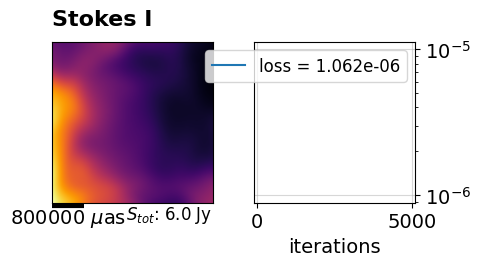

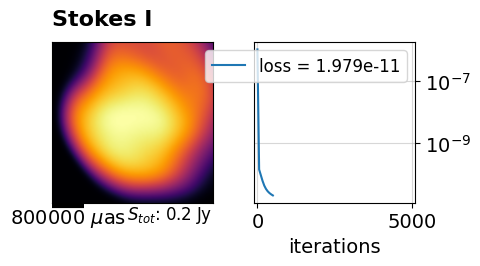

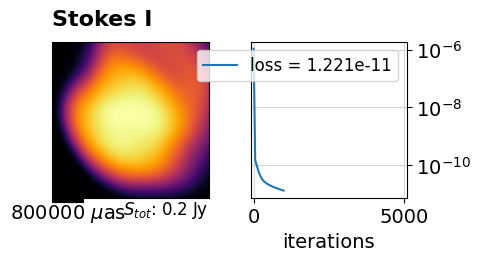

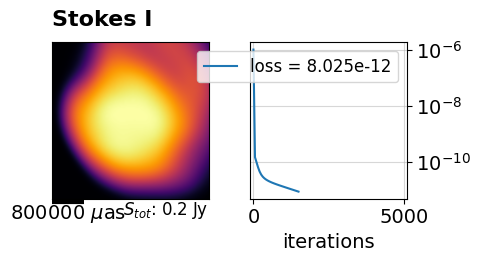

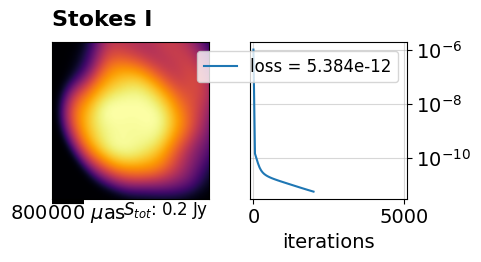

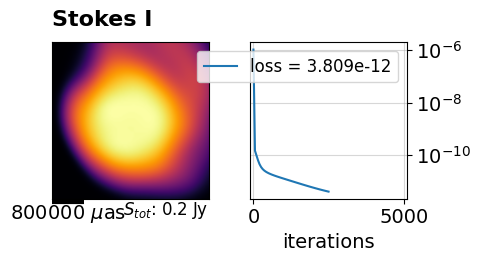

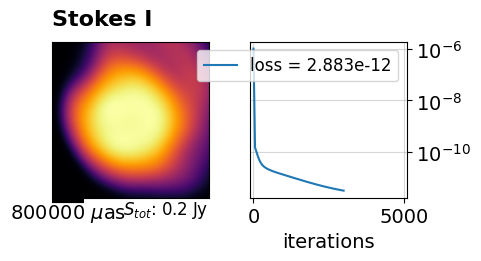

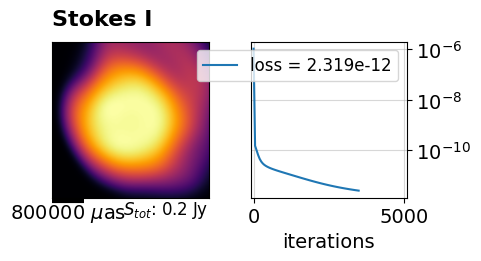

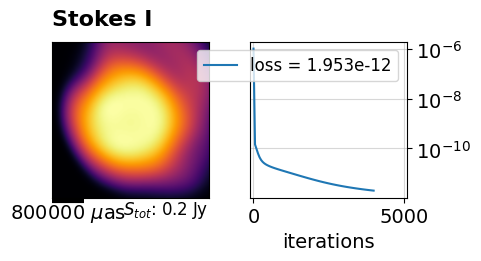

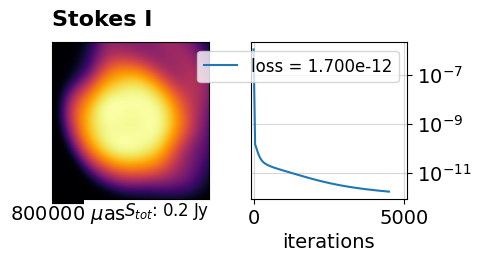

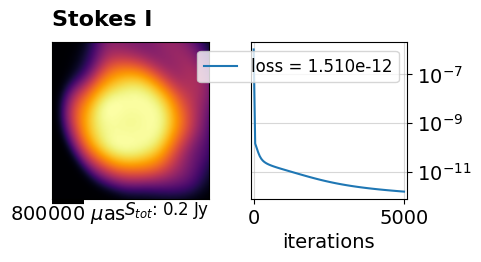

In [13]:
# Show progress updates
def show_progress(image, outpath):
    image.plot(outpath=outpath, scale='log')
    display(IPImage(outpath))
    plt.close('all')

# Fix jax version issue (Only needed in Colab)
if not hasattr(jax, 'tree_map'):
    jax.tree_map = jax.tree.map

print('Initialization...')

# Create initialization image
init_im = vi.Image(npix, fov, obs.ra, obs.dec, initniter)
init_im.add_tophat(totflux, init_params)
init_im.plot(outpath='./init_image.png')

# Create empty Image object and initialize loss function
# Initialize image and loss
init = vi.Image(npix, fov, obs.ra, obs.dec, initniter)
lloss, loss = [], 0

# Initialization training
for i in (pbar := tqdm(range(1, initniter+1))):
    pbar.set_description(f'Loss {loss:.1e}')

    # Apply one training step
    loss, _, out, state = tr.Trainer.train_step(
        odict(
            state=state,
            grid=grid,
            init_arr=init_im.iarr
        )
    )

    # Save loss
    lloss.append(loss)

    # Show initialization progress
    if i == 1 or i % 500 == 0 or i == initniter:
        init.from_image(out, loss=lloss)
        show_progress(image=init, outpath='./output_init.png')

### Step 5: Run the optimization

Training...


  0%|          | 0/5000 [00:00<?, ?it/s]

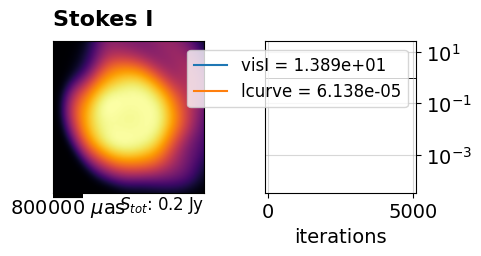

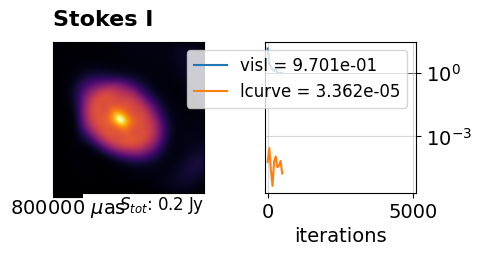

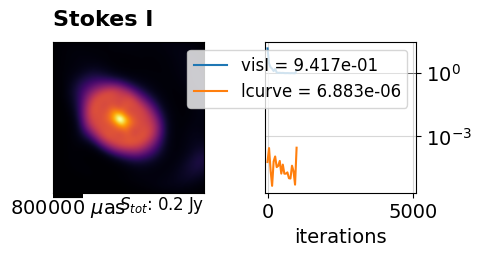

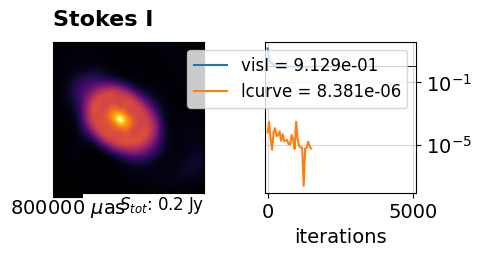

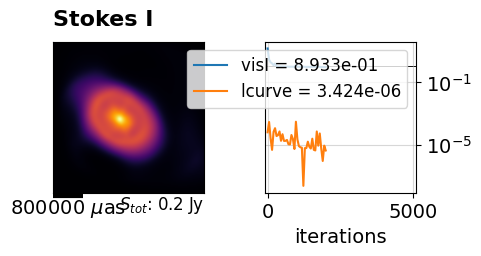

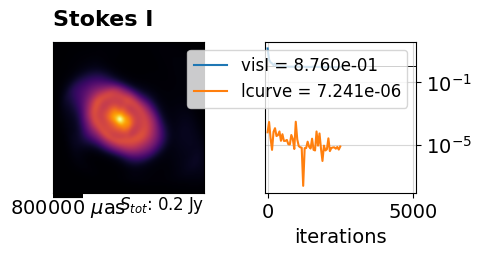

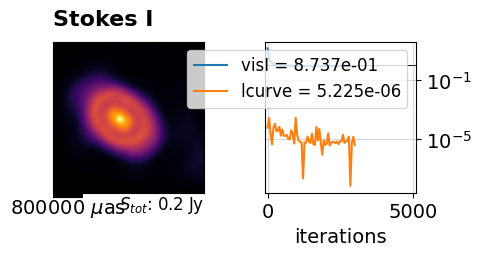

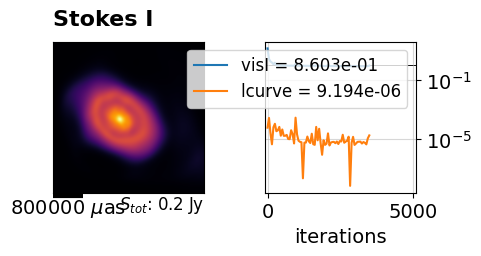

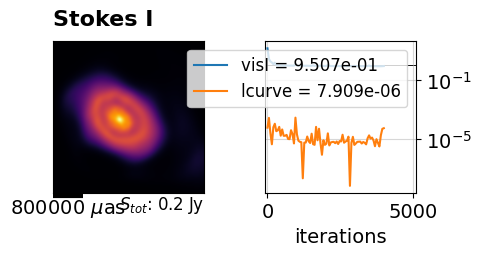

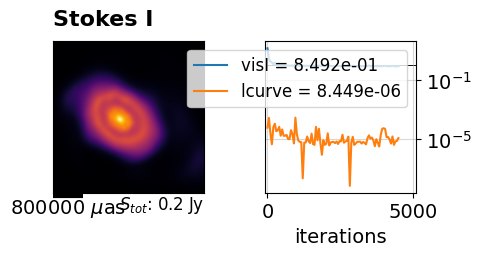

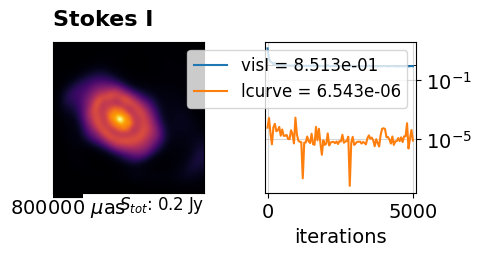

In [14]:
print('Training...')

# Create empty Image object and initialize loss function
image = vi.Image(npix, fov, obs.ra, obs.dec, niter)
lloss, loss = {dp: [] for dp in data_prod} | {'lcurve': []}, 0

# Optimization training
for i in (pbar := tqdm(range(1, niter+1))):
    pbar.set_description(f'Loss {loss:.1e}')

    # Apply one training step
    loss, ldict, out, state = tr.Trainer.train_step(
        odict(
            state=state,
            grid=grid,
            data=data,
            lcurve=jnp.array([totflux]),
        )
    )

    # Save loss
    for l in lloss.keys():
        lloss[l].append(ldict[l])

    # Show initialization progress
    if i == 1 or i % 500 == 0 or i == initniter:
        image.from_image(out, loss=lloss)
        show_progress(image=image, outpath='./output_train.png')

### Step 6: Save the final image
1. Resample the network on a finer spatial grid
2. Save the final image

Saving results...


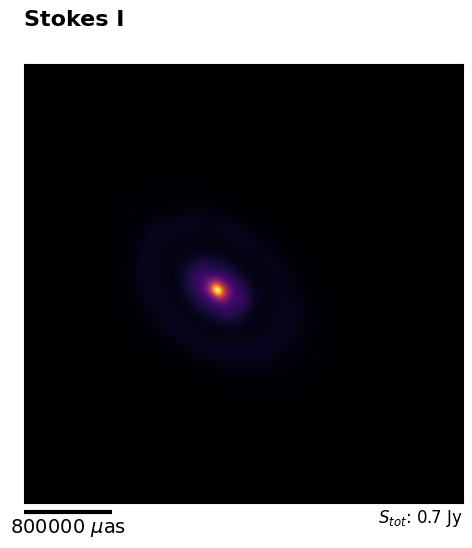

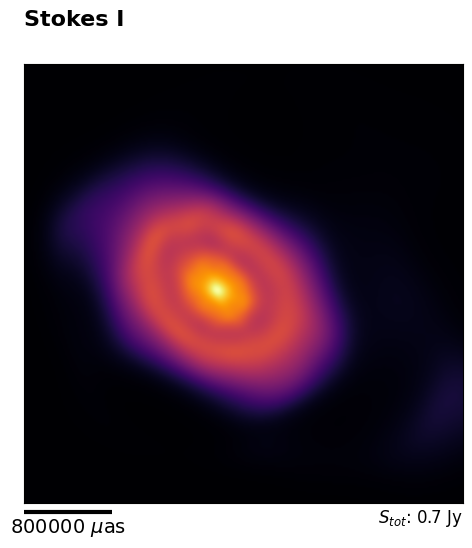

In [15]:
# Save image after optimization
print('Saving results...')

# Sample output image on a finer grid
grid_out = ut.get_grid(npix_out, npix_out)

# Generate output image
image = vi.Image(npix_out, fov, obs.ra, obs.dec, niter)
image.from_state(state, grid_out)
image.plot(outpath='./output_image.png')
image.plot(outpath='./output_image_log.png', scale='log')
image.save_fits('./output_image.fits')
display(IPImage('./output_image.png'))
display(IPImage('./output_image_log.png'))
plt.close('all')